
Evaluates out-of-sample Solar Cycle 24 reconstruction and Forbush Decrease recovery under strict 54-day purged blocked validation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
bench = pd.read_csv('../data/processed/model_benchmark_sc24.csv')
preds = pd.read_parquet('../data/processed/sc24_predictions.parquet')
bench

,Model,R2,RMSE,MAE,FD_Recovery_Pct,PICP_95_Pct,RMSE_Reduction_vs_Base_Pct
0,Climatology / Cycle Persistence,0.3825,2.8623,2.2990,55.08,NaN,0.00
1,Huber Robust Linear Baseline,0.7132,1.9505,1.6104,87.52,76.30,31.86
2,Random Forest (Blocked CV),0.4414,2.7224,2.2298,54.78,65.42,4.89
3,Hybrid LightGBM + Heteroscedastic GP/Var,0.5621,2.4104,1.9688,78.78,12.67,15.79


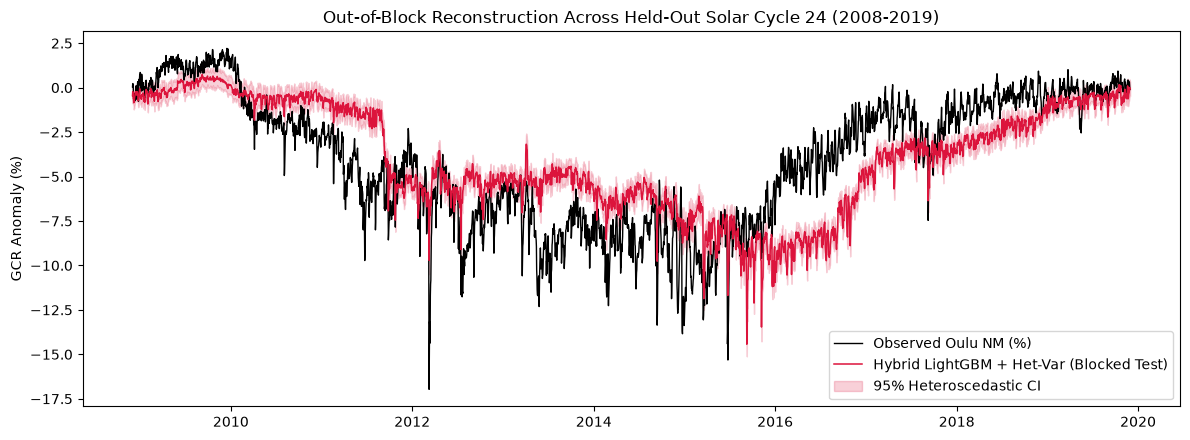

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(preds.index, preds['y_true'], color='black', lw=1.0, label='Observed Oulu NM (%)')
ax.plot(preds.index, preds['pred_hybrid'], color='crimson', lw=1.1, label='Hybrid LightGBM + Het-Var (Blocked Test)')
ax.fill_between(preds.index, preds['hybrid_lower95'], preds['hybrid_upper95'], color='crimson', alpha=0.2, label='95% Heteroscedastic CI')
ax.set_title('Out-of-Block Reconstruction Across Held-Out Solar Cycle 24 (2008-2019)')
ax.set_ylabel('GCR Anomaly (%)')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/fig02_sc24_blocked_reconstruction.png', dpi=180)
plt.show()